# Milestone 1: Formula 1 Podium Prediction Companion

This run-all notebook predicts whether each driver finishes on the podium using only information known after qualifying and before the race. The primary metric is **PR-AUC** because podiums are rare; ROC-AUC is secondary. Threshold-dependent F1, precision, and recall are also reported. The chronological split is train through 2019, validation in 2020-2021, and unseen test in 2022-2024.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import display, Image
from f1podium.pipeline import run_analysis
results = run_analysis(ROOT / 'data' / 'raw', ROOT / 'artifacts')
print(results['summary'])

{'diagnostics': {'raw_result_rows': 26759, 'duplicate_driver_race_groups': 85, 'clean_rows': 26668, 'unique_grain': True, 'year_min': 1950, 'year_max': 2024}, 'thresholds': {'Logistic regression': 0.655, 'Random forest': 0.64, 'Shallow neural network': 0.24}, 'inference_demos': {'model': 'Shallow neural network', 'complete_record': {'podium_probability': 0.08661545099344505, 'predicted_podium': False, 'threshold': 0.24}, 'partial_record': {'podium_probability': 0.03189925681062999, 'predicted_podium': False, 'threshold': 0.24}}}


## 1. Raw audit and cleaning

The raw CSVs are never modified. Literal `\N` sentinels become missing values on read; dates and qualifying durations receive semantic types. Primary keys and major foreign keys are checked programmatically. Shared-drive duplicates are resolved by keeping a car the driver actually started (`grid > 0`), then the best final classification, then the smallest result ID. This retains pre-race entrant identity and is deterministic.

In [2]:
display(results['pk_audit'])
display(results['fk_audit'])
display(results['summary']['diagnostics'])

,table,key,rows,null_keys,duplicate_keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,constructor_results,constructorResultsId,12625,0,0
3,constructor_standings,constructorStandingsId,13391,0,0
4,drivers,driverId,861,0,0
5,driver_standings,driverStandingsId,34863,0,0
6,races,raceId,1125,0,0
7,results,resultId,26759,0,0
8,qualifying,qualifyId,10494,0,0
9,seasons,year,75,0,0


,relationship,checked,orphans
0,races.circuitId -> circuits.circuitId,1125,0
1,results.raceId -> races.raceId,26759,0
2,results.driverId -> drivers.driverId,26759,0
3,results.constructorId -> constructors.construc...,26759,0
4,results.statusId -> status.statusId,26759,0
5,qualifying.raceId -> races.raceId,10494,0
6,qualifying.driverId -> drivers.driverId,10494,0
7,driver_standings.raceId -> races.raceId,34863,0
8,constructor_standings.raceId -> races.raceId,13391,0


{'raw_result_rows': 26759,
 'duplicate_driver_race_groups': 85,
 'clean_rows': 26668,
 'unique_grain': True,
 'year_min': 1950,
 'year_max': 2024}

## 2. EDA before and after cleaning

The audit above quantifies raw integrity. After cleaning, `(raceId, driverId)` is unique. Qualifying coverage changes sharply over history, so we preserve an explicit missingness flag and use grid position as the historically available anchor instead of dropping older seasons.

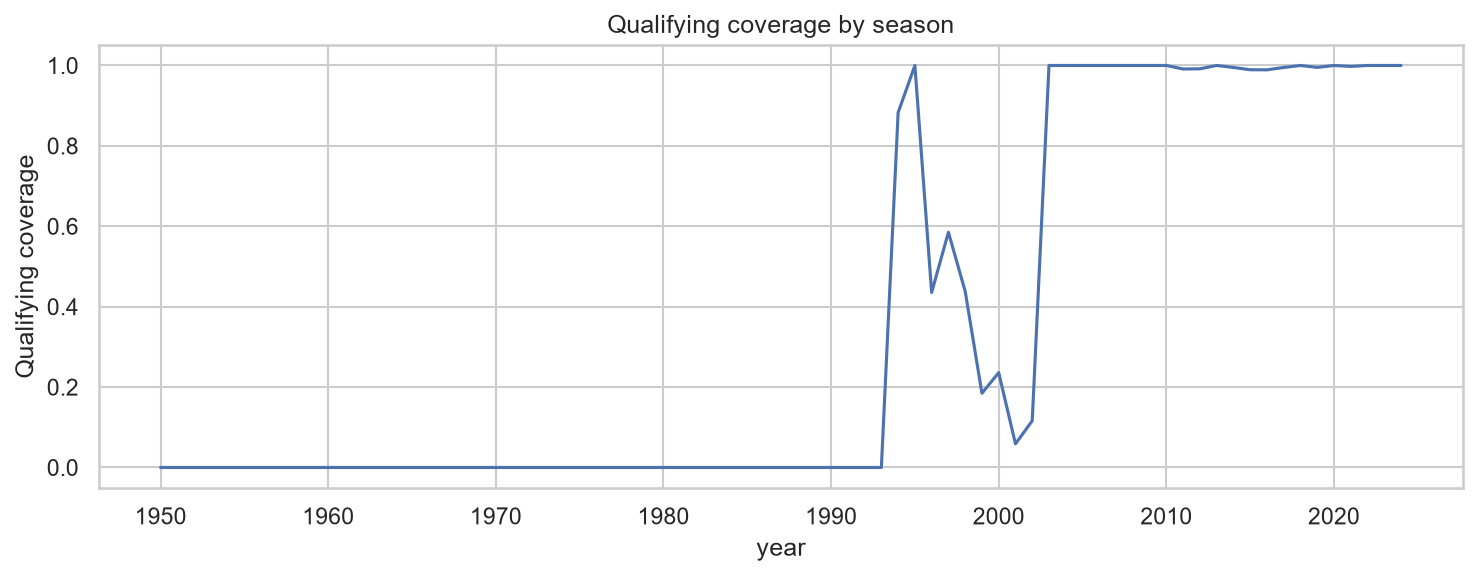

In [3]:
display(Image(filename=str(ROOT / 'artifacts/figures/qualifying_coverage.png')))

## 3. Data-engineering questions

Each answer uses multi-hop joins. Question 1 joins results, races, and circuits and uses **grid**, not qualifying order, to define a front-row start; qualifying position remains separate. Question 2 joins drivers and circuits, maps nationality to country, and stratifies by grid band to control starting position. Question 3 joins results, status, and constructors; only documented component-failure statuses count as mechanical.


 front_row_circuits


,era,circuit_name,mean,count
23,1950-2013,Circuit de Nevers Magny-Cours,0.805556,36
37,1950-2013,Istanbul Park,0.785714,14
30,1950-2013,Dijon-Prenois,0.750000,12
16,1950-2013,Circuit Bremgarten,0.700000,10
60,1950-2013,Sepang International Circuit,0.700000,30
63,1950-2013,Suzuka Circuit,0.700000,50
35,1950-2013,Hungaroring,0.678571,56
12,1950-2013,Bahrain International Circuit,0.666667,18
11,1950-2013,Autódromo do Estoril,0.653846,26
21,1950-2013,Circuit de Barcelona-Catalunya,0.652174,46



 home_effect


,grid_band,home_race,mean,count
0,1-3,False,0.556536,3060
1,1-3,True,0.549242,264
2,4-6,False,0.263263,3016
3,4-6,True,0.246154,260
4,7-10,False,0.095489,3990
5,7-10,True,0.087855,387
6,11-15,False,0.030813,4933
7,11-15,True,0.034115,469
8,16+,False,0.007532,6904
9,16+,True,0.007479,936



 mechanical_retirements


,era,constructor_name,mean,sum,count
4,2014-2021,Caterham,0.235294,8,34
8,2014-2021,Lotus F1,0.171053,13,76
17,2014-2021,Toro Rosso,0.152893,37,242
15,2014-2021,Renault,0.125000,25,200
11,2014-2021,McLaren,0.118750,38,320
16,2014-2021,Sauber,0.110000,22,200
14,2014-2021,Red Bull,0.106250,34,320
13,2014-2021,Racing Point,0.105263,8,76
1,2014-2021,AlphaTauri,0.102564,8,78
10,2014-2021,Marussia,0.096774,3,31


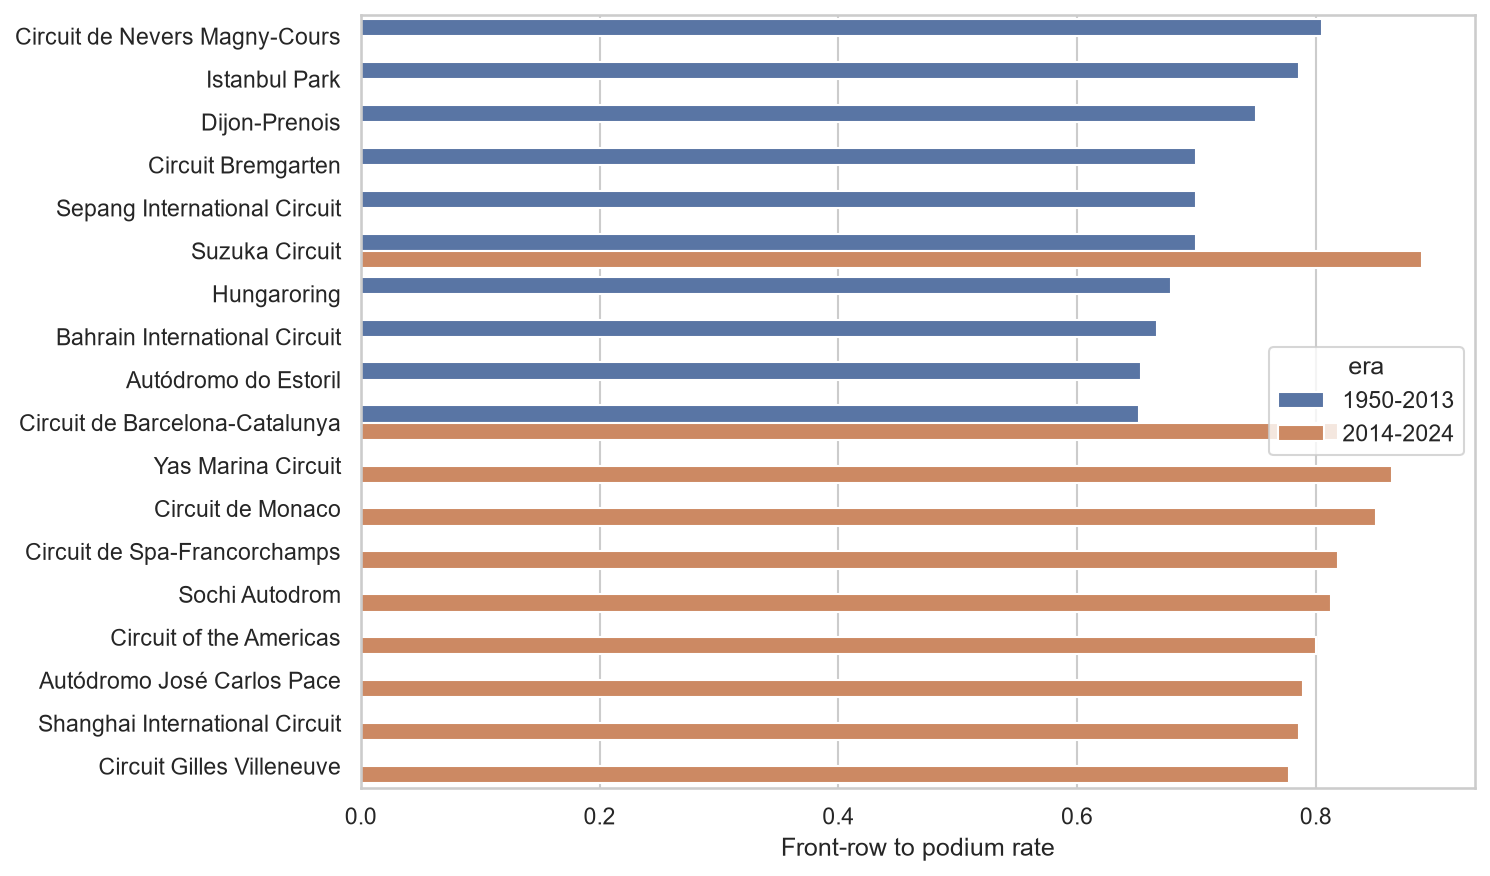

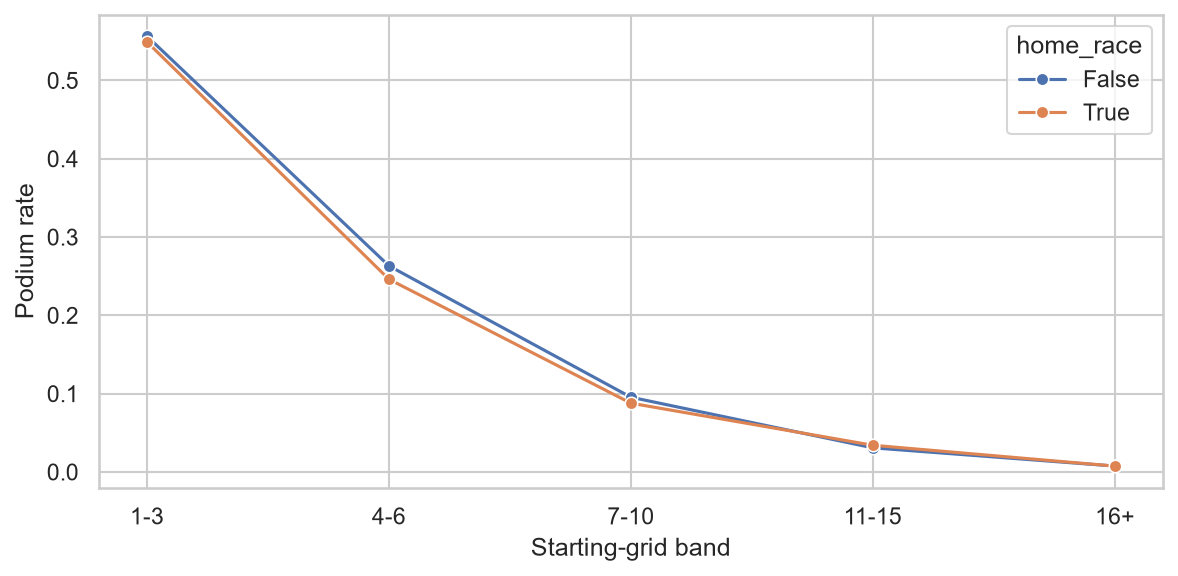

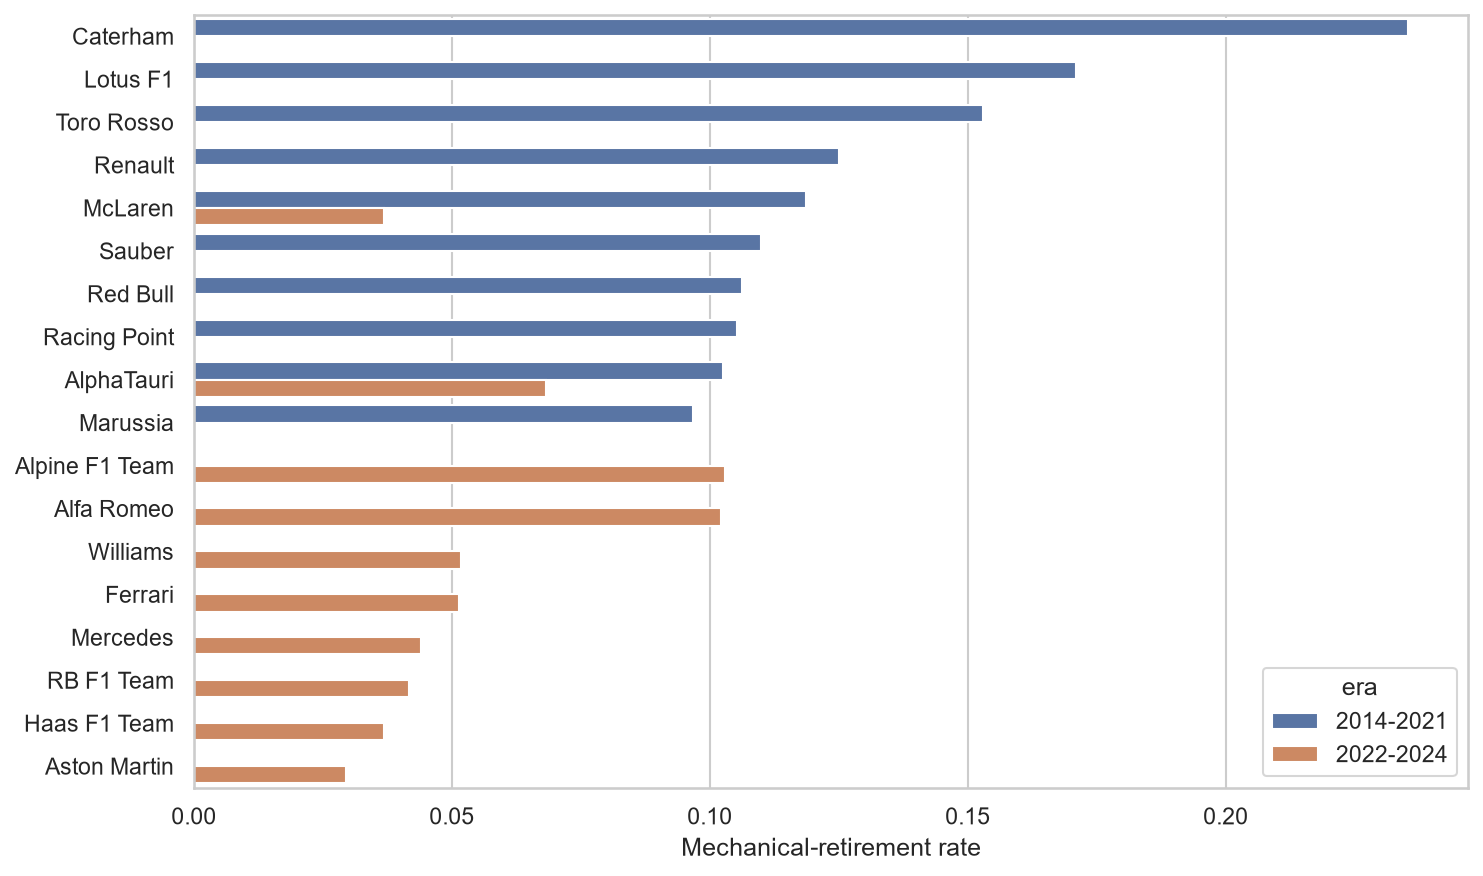

In [4]:
for key, table in results['answers'].items():
    print('\n', key)
    display(table.groupby('era').head(10) if 'era' in table else table)
for name in ['front_row_conversion', 'home_effect', 'mechanical_retirements']:
    display(Image(filename=str(ROOT / f'artifacts/figures/{name}.png')))

## 4. Leakage-safe feature engineering and split

Grid, pit-lane indicator, field size, qualifying order/time/missingness, age, season context, and **lagged** driver/constructor form are pre-race features. Standings are shifted to the next race within the same season. Rolling form uses `shift()` before `rolling()`, so the current target cannot leak into its own predictors. Post-race position, points, laps, status, pit stops, and fastest lap never enter the feature matrix.

In [5]:
from f1podium.pipeline import FEATURES, FEATURE_GROUPS, split_by_time
display(FEATURE_GROUPS)
splits = split_by_time(results['modeling_table'])
display({name: (len(part), int(part.year.min()), int(part.year.max()), float(part.podium.mean())) for name, part in splits.items()})

{'grid': ['grid_position', 'pit_lane_start', 'front_row', 'field_size'],
 'qualifying': ['qualifying_position',
  'qualifying_time_seconds',
  'qualifying_missing'],
 'form': ['driver_podium_rate_5',
  'constructor_podium_rate_5',
  'driver_races_before'],
 'standings': ['driver_points_before',
  'driver_rank_before',
  'constructor_points_before',
  'constructor_rank_before'],
 'context': ['driver_age', 'round', 'year']}

{'train': (24529, 1950, 2019, 0.1253210485547719),
 'validation': (780, 2020, 2021, 0.15),
 'test': (1359, 2022, 2024, 0.15011037527593818)}

## 5. Preprocessing experiments

Median imputation plus scaling is compared with median without scaling and zero imputation plus scaling. These are full-pipeline validation experiments; the test set remains untouched.

In [6]:
display(results['preprocessing'])

,preprocessing,validation_ROC-AUC,validation_PR-AUC
0,median + scaling,0.925849,0.727587
1,"median, no scaling",0.924392,0.724075
2,zero + scaling,0.926815,0.724504


## 6. Comparable models and evaluation

Logistic regression is the interpretable baseline, random forest captures nonlinear interactions, and a two-hidden-layer MLP is the required shallow neural network. All use identical rows and features. Hyperparameters and F1 thresholds are fixed using train/validation data only; the final test set is evaluated once.

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic regression,train,0.655,0.906245,0.561044,0.580015,0.467877,0.762850
1,Logistic regression,validation,0.655,0.925849,0.727587,0.703125,0.647482,0.769231
2,Logistic regression,test,0.655,0.935048,0.702575,0.667910,0.539157,0.877451
3,Random forest,train,0.640,0.988227,0.919217,0.828873,0.826593,0.831165
4,Random forest,validation,0.640,0.924070,0.702107,0.709091,0.757282,0.666667
5,Random forest,test,0.640,0.932883,0.689406,0.659898,0.684211,0.637255
6,Shallow neural network,train,0.240,0.912097,0.585417,0.577556,0.461718,0.770982
7,Shallow neural network,validation,0.240,0.928182,0.738457,0.712551,0.676923,0.752137
8,Shallow neural network,test,0.240,0.937913,0.716215,0.669355,0.568493,0.813725


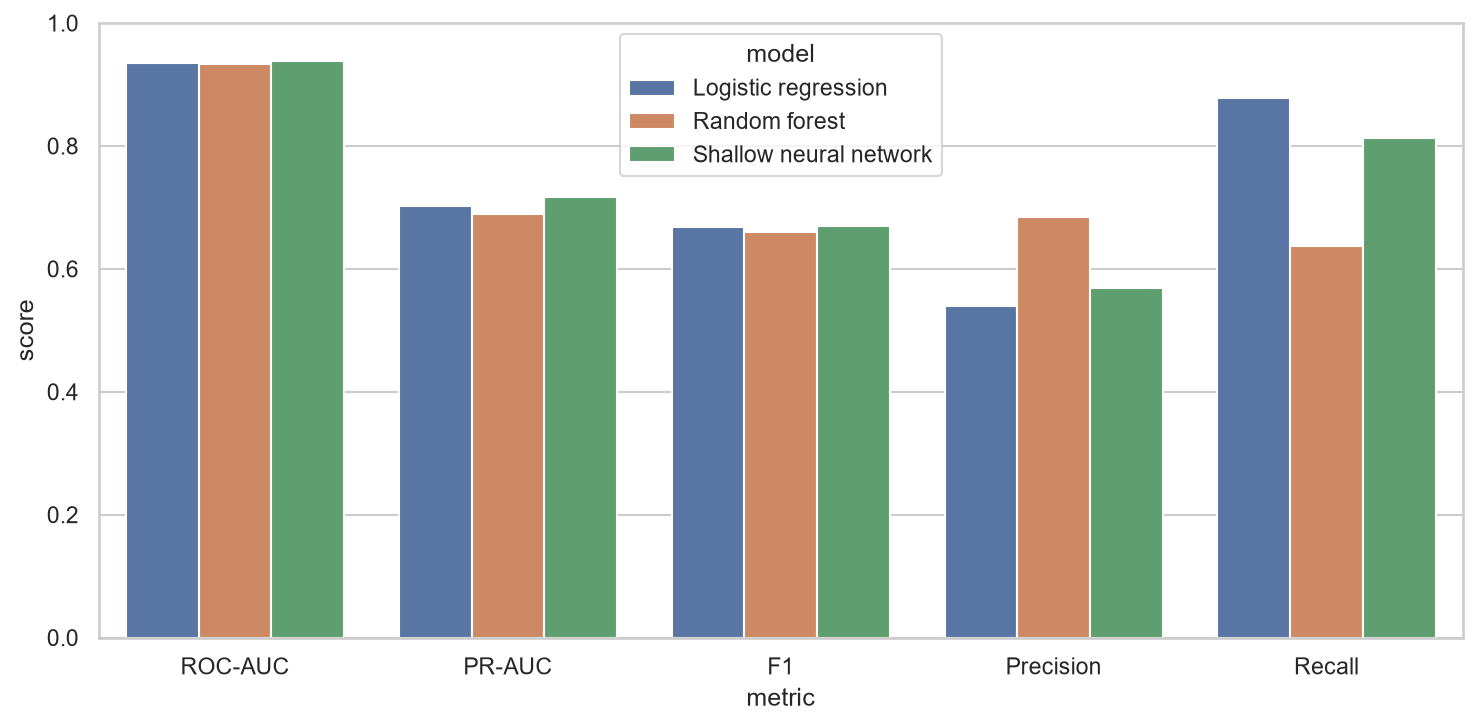

In [7]:
display(results['metrics'])
display(Image(filename=str(ROOT / 'artifacts/figures/model_comparison.png')))

## 7. Feature-group ablation

One group is removed at a time from the logistic baseline. The change in validation PR-AUC measures predictive contribution after training and complements the earlier EDA motivation.

,variant,features,validation_PR-AUC,validation_ROC-AUC,PR-AUC_change
0,all features,17,0.727587,0.925849,0.000000
1,without grid,13,0.701751,0.920537,-0.025837
2,without qualifying,14,0.722284,0.924186,-0.005304
3,without form,14,0.719699,0.923245,-0.007889
4,without standings,13,0.712215,0.923605,-0.015372
5,without context,14,0.723246,0.924572,-0.004342


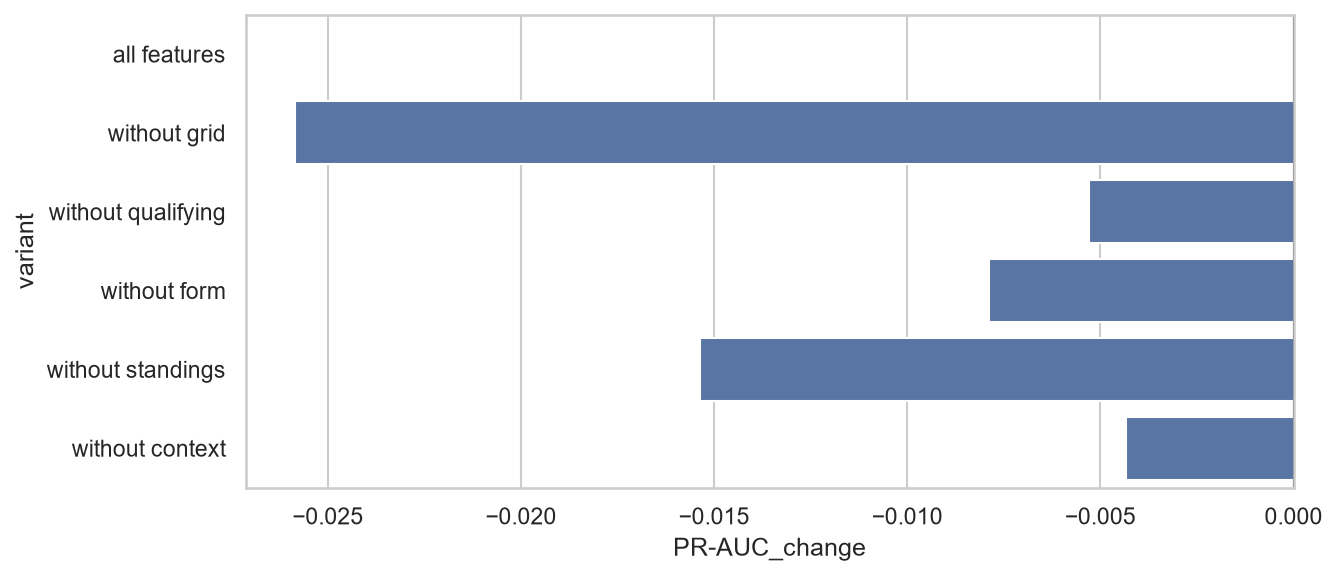

In [8]:
display(results['ablations'])
display(Image(filename=str(ROOT / 'artifacts/figures/ablation.png')))

## 8. Explainability

Permutation importance and global SHAP summarize reliance across many validation rows. Local SHAP explains one validation prediction. **These associations are not causal effects:** importance means the fitted model relied on a feature, not that changing it would cause a podium.

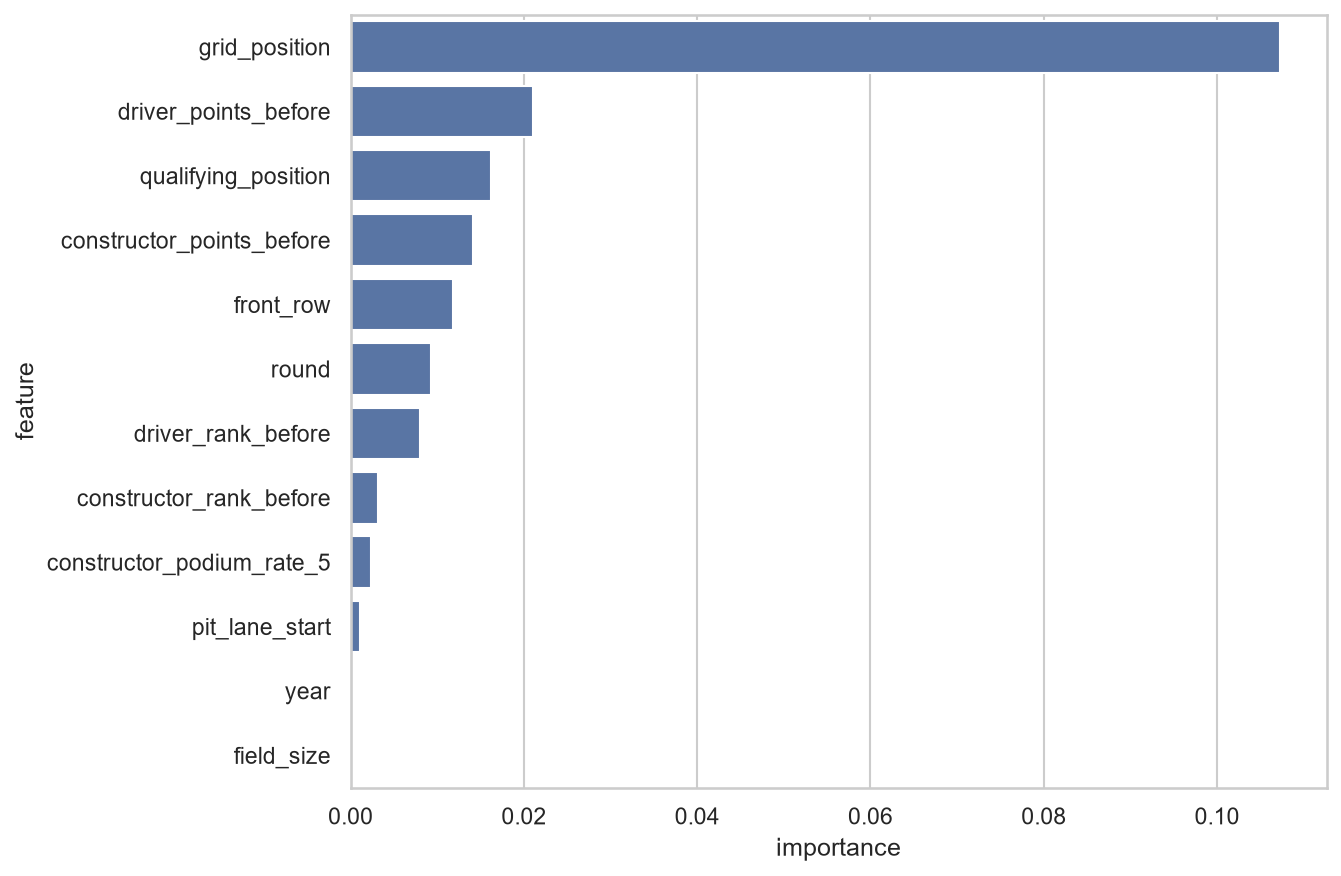

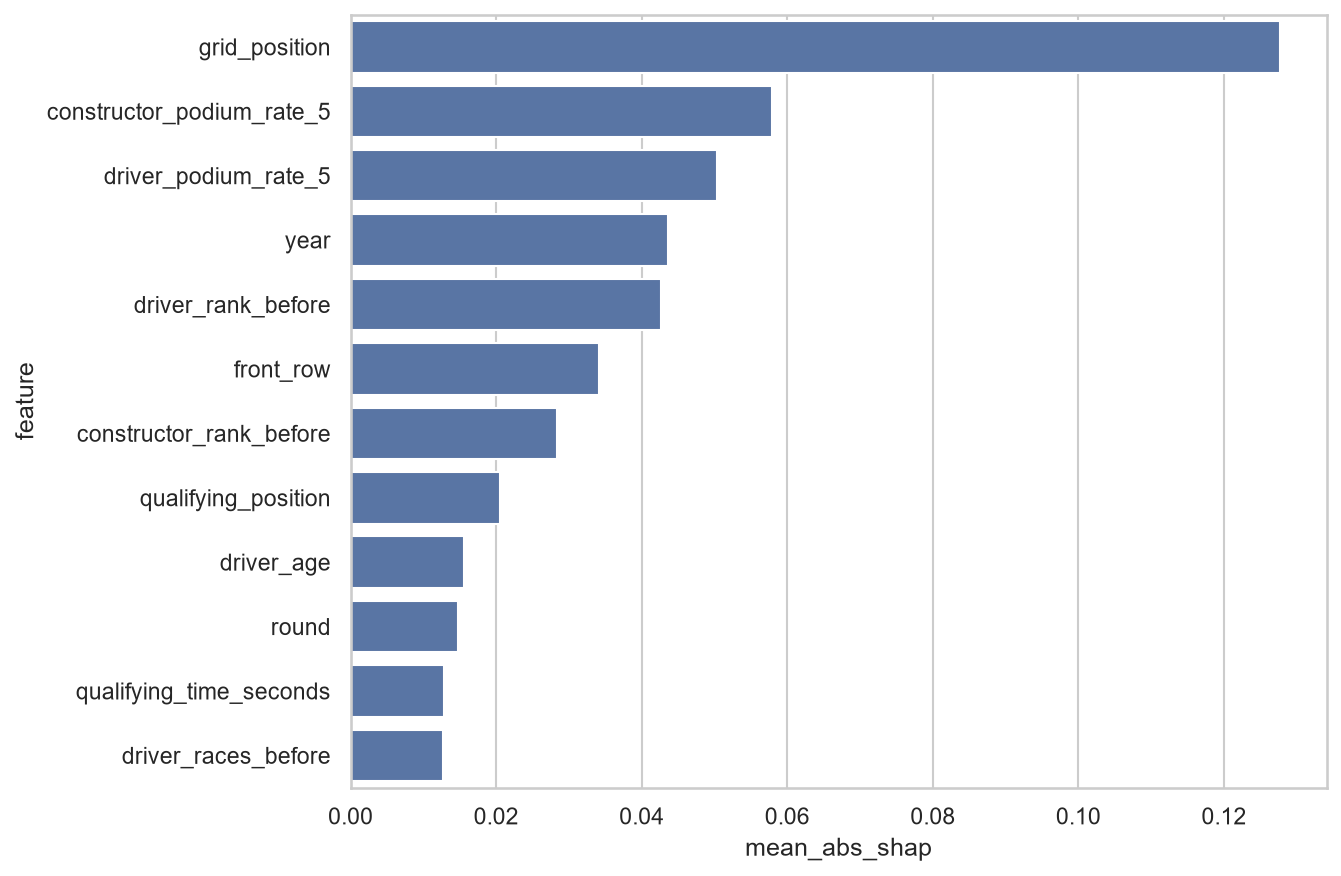

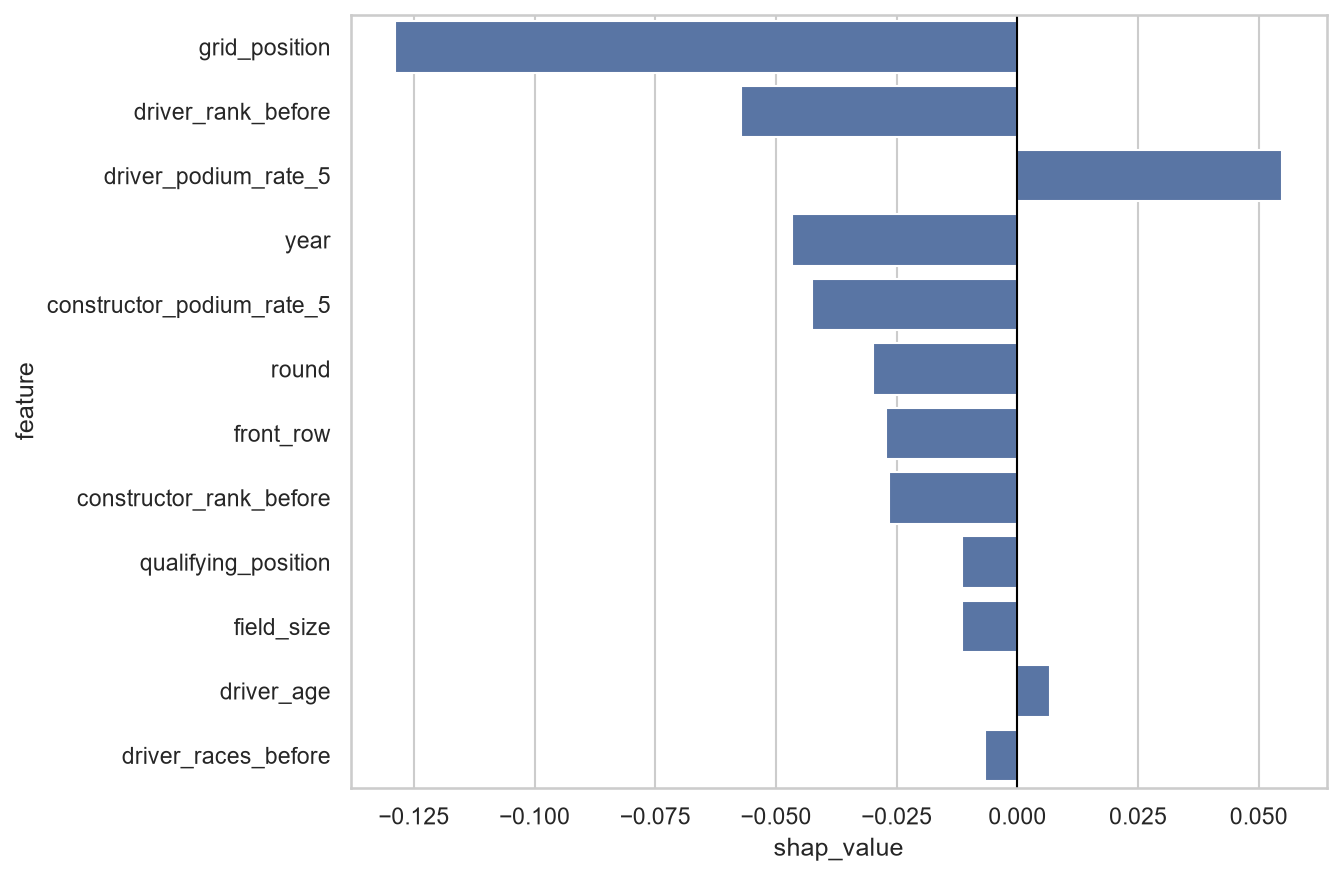

,feature,mean_abs_shap
0,grid_position,0.127701
8,constructor_podium_rate_5,0.057899
7,driver_podium_rate_5,0.050338
16,year,0.043620
11,driver_rank_before,0.042629
2,front_row,0.034164
13,constructor_rank_before,0.028380
4,qualifying_position,0.020544
14,driver_age,0.015563
15,round,0.014799


,feature,shap_value,observed_value
0,grid_position,-0.128913,11.0
11,driver_rank_before,-0.057282,15.0
7,driver_podium_rate_5,0.054841,0.2
16,year,-0.046582,2021
8,constructor_podium_rate_5,-0.042630,0.1
15,round,-0.030000,13
2,front_row,-0.027297,0
13,constructor_rank_before,-0.026648,8.0
4,qualifying_position,-0.011446,11.0
3,field_size,-0.011370,20


In [9]:
for name in ['permutation_importance', 'shap_global', 'shap_local']:
    display(Image(filename=str(ROOT / f'artifacts/figures/{name}.png')))
display(results['shap_global'].head(12))
display(results['shap_local'].head(12))

## 9. Inference demonstrations

The reusable function accepts a complete record or a partial record. Missing fields use the training-fitted imputer; the returned threshold is the validation-selected threshold for the chosen model.

In [10]:
display(results['summary']['inference_demos'])

{'model': 'Shallow neural network',
 'complete_record': {'podium_probability': 0.08661545099344505,
  'predicted_podium': False,
  'threshold': 0.24},
 'partial_record': {'podium_probability': 0.03189925681062999,
  'predicted_podium': False,
  'threshold': 0.24}}

## 10. Limitations

- Historical qualifying coverage is sparse, especially before the modern qualifying tables.
- Constructor IDs do not bridge team renames; history intentionally resets at identity changes.
- Nationality-to-country mapping is necessarily incomplete and does not represent multiple citizenships.
- Status classification is a documented rules-based grouping and may miss ambiguous rare failures.
- Era changes and the small 2020-2021 validation window create distribution shift.
- Predictions are associations from historical data, not causal claims or guarantees.